# RandomForestRegressor Hyperparameter Selection

## Import and Load

No subbasins, using elevation as a feature. 

In [ ]:
import sys
from pathlib import Path

# Set root
cwd = Path.cwd()
ROOT = next(p for p in [cwd, *cwd.parents] if (p / ".git").exists())
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from src.features.preprocessing import load_model_data
from src.evaluation import splits, leakage
from src.evaluation.make_splits import load_split, SPLITS

SPLIT_LIST = list(SPLITS)

from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import RandomForestClassifier 
from sklearn.ensemble import ExtraTreesRegressor
from sklearn.ensemble import ExtraTreesClassifier

In [ ]:
# ===== Settings: change these, then Restart & Run All =====
SPLIT = "10km"            # "10km", "10km_subbasin", "7.5km_subbasin", "5km_subbasin"
USE_SUBBASIN = False      # True: subbasin features replace elevation
MODEL_SEED = 0
THRESHOLD_MG_L = 10
DROP_ELEVATION = True      # True: remove elevation_m

In [ ]:
# Load the cleaned/merged dataset

X, y, meta = load_model_data(subbasin=USE_SUBBASIN,  drop_elevation=DROP_ELEVATION)
FEATURES = list(X.columns)

data = load_split(pd.concat([meta, X], axis=1).assign(log_nitrate=y), split=SPLIT)
print(f"split={SPLIT} | subbasin features={USE_SUBBASIN} | {len(FEATURES)} features")
print(data["fold"].value_counts().sort_index().to_dict(), "| holdout rows:", int(data["holdout"].sum()))


split=10km | subbasin features=False | 50 features
{0: 1035, 1: 972, 2: 1143, 3: 1041, 4: 1089} | holdout rows: 1089


In [4]:
# Set the training folds and the holdout

train_val = data[~data["holdout"]].reset_index(drop=True)       # Training set with 4 folds

X_tv = train_val[FEATURES]
y_tv = train_val["log_nitrate"]

# Print the sizes of the training folds
print(train_val["fold"].value_counts().sort_index().to_dict())

X_tv.info()

{0: 1035, 1: 972, 2: 1143, 3: 1041}
<class 'pandas.DataFrame'>
RangeIndex: 4191 entries, 0 to 4190
Data columns (total 50 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   gm_well_category                           4191 non-null   int64  
 1   soil_slopegradwta                          4191 non-null   float64
 2   soil_aws0150wta                            4191 non-null   float64
 3   soil_hydgrpdcd_pct_a                       4151 non-null   float64
 4   soil_hydgrpdcd_pct_b                       4151 non-null   float64
 5   soil_hydgrpdcd_pct_c                       4151 non-null   float64
 6   elevation_m                                4191 non-null   float64
 7   topographic_position                       4191 non-null   float64
 8   pct_veg_berry_500m                         4171 non-null   float64
 9   pct_vineyard_500m                          4171 non-null   float64
 10 

# RandomForestRegressor

## Hyperparameter Selection
We need to optimize the hyperparameters `n_estimators` `max_depth` `max_features`

Because we have hyperparameters, we need to use nested CV. 

In [5]:
from src.models import random_forest
development, X_dev, y_dev = random_forest.make_inner_subfolds(data, FEATURES, N_SUBFOLDS = 4, THRESHOLD_MG_L = 10, SEED = 77)

subfold    0    1    2    3
fold                       
0        187  195  237  416
1        109  194  230  439
2        408  258  302  175
3        186  160  224  471


In [6]:
param_grid = {
"n_estimators": [10, 50, 100, 300, 500],
"max_features": [1.0, "sqrt", "log2", 0.5],  
"max_depth" : [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
}
#"n_estimators": the number of decision trees in the random forest.
#"max_features": how many predictor features a tree can consider when searching for the best split.
#   1.0: consider all predictor features at each split.
#   "sqrt": consider approximately the square root of the number of features.
#   "log2" : consider log2 of the number of features.
#   0.5: consider 50% of the available features.

In [7]:
from sklearn.model_selection import GridSearchCV # type: ignore

def make_search_RFR(inner_cv, param_grid, SEED):
    return GridSearchCV(
        estimator=RandomForestRegressor(
            random_state=SEED,
            n_jobs=1,
        ),
        param_grid=param_grid,
        scoring="neg_root_mean_squared_error",
        cv=inner_cv,
        refit=True,
        n_jobs=-1,
    )

In hyperparameter selection, the randomness has an appreciable impact. I'm going to run 100 different random seeds and pick out the most frequent best hyperparameters. 

In [8]:
## This is going to take forever to run (885 min)

all_best_params = []

for seed in range(1): ##99
    outer_results, best_params_by_fold = (
        random_forest.fit_model_with_nested_cv(
            development,
            X_dev,
            y_dev,
            param_grid,
            make_search_RFR,
            N_SUBFOLDS=4,
            THRESHOLD_MG_L=10,
            SEED=seed,
        )
    )

    # Record the seed for each outer fold's best parameters
    params = best_params_by_fold.copy()
    params["seed"] = seed

    all_best_params.append(params)

all_best_params = pd.concat(all_best_params, ignore_index=True)
display(all_best_params)


,outer_fold,max_depth,max_features,n_estimators,seed
0,0,12,sqrt,100,0
1,1,14,sqrt,500,0
2,2,2,0.5,10,0
3,3,11,sqrt,100,0


In [9]:
# save file 
#all_best_params.to_csv("all_best_params_1.csv")

#alternatively read file 
all_best_params = pd.read_csv("all_best_params_1.csv")

In [10]:
# Frequency of each selected hyperparameter
for param in ["max_depth", "max_features", "n_estimators"]:
    print(f"\nSelection frequency for {param}:")
    print(
        all_best_params[param]
        .value_counts(normalize=True)
        .mul(100)
        .round(2)
        .astype(str)
        .add("%")
    )


Selection frequency for max_depth:
max_depth
11    25.76%
10    14.65%
2     13.89%
9      9.34%
4      7.83%
5      7.07%
8      6.57%
6      6.31%
7      4.55%
3      4.04%
Name: proportion, dtype: str

Selection frequency for max_features:
max_features
sqrt    46.46%
log2    30.81%
0.5     22.47%
1.0      0.25%
Name: proportion, dtype: str

Selection frequency for n_estimators:
n_estimators
50     27.78%
100    20.45%
300    19.95%
500    18.69%
10     13.13%
Name: proportion, dtype: str


This suggests `max_features='sqrt'` `n_estimators=300` `max_depth=11`. 

In [11]:
n_ran = 10
output = np.zeros((4*n_ran,3))

for i, N_EST in enumerate([100, 300, 500, 700]):
    for j, RAN in enumerate(range(1,11)):
        row = i * n_ran + j 
        model = RandomForestRegressor(n_estimators=N_EST, max_features='sqrt', max_depth=9, random_state=RAN, n_jobs=1)
        overall_rmse = random_forest.fit_model_with_normal_cv(development, X_dev, y_dev, model, THRESHOLD_MG_L = 10)
        output[row, 0] = N_EST
        output[row, 1] = RAN
        output[row, 2] = overall_rmse

print(output)


TypeError: float() argument must be a string or a real number, not 'dict'

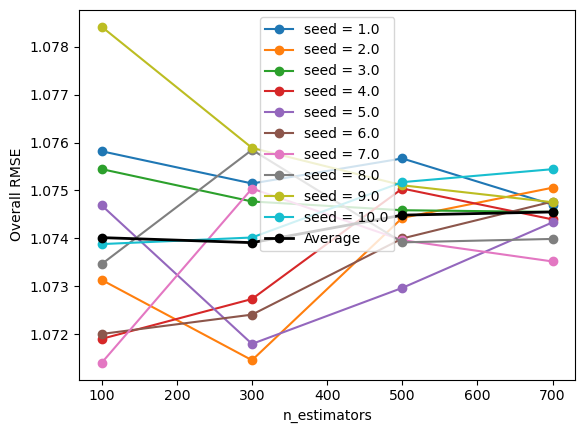

n_estimators with minimum average RMSE: 300.0 1.0739103128546759


In [ ]:
#Create slices for plotting
values = np.unique(output[:, 1])

for value in values:
    rows = output[output[:, 1] == value]
    rows = rows[np.argsort(rows[:, 0])]  # sort x-values for a clean line

    plt.plot(rows[:, 0], rows[:, 2], marker="o", label=f"seed = {value}")

# Average across seeds for each N_DEP (column 0)
n_deps = np.unique(output[:, 0])

avg_rows = np.array([
    [n_dep, output[output[:, 0] == n_dep, 2].mean()]
    for n_dep in n_deps
])

plt.plot(avg_rows[:, 0], avg_rows[:, 1],
        marker="o", color="black", linewidth=2, label="Average")

            
# Find the N_DEP with the lowest average
min_idx = np.argmin(avg_rows[:, 1])

plt.xlabel("n_estimators")
plt.ylabel("Overall RMSE")
plt.legend()
plt.show()

print("n_estimators with minimum average RMSE:", avg_rows[min_idx, 0], avg_rows[min_idx, 1])

In [ ]:
n_ran = 10
output = np.zeros((15*n_ran,3))

for i, N_DEP in enumerate(range(1, 16)):
    for j, RAN in enumerate(range(1,11)):
        row = i * n_ran + j 
        model = RandomForestRegressor(n_estimators=300, max_features='sqrt', max_depth=N_DEP, random_state=RAN, n_jobs=1)
        overall_rmse = random_forest.fit_model_with_normal_cv(development, X_dev, y_dev, model, THRESHOLD_MG_L = 10)
        output[row, 0] = N_DEP
        output[row, 1] = RAN
        output[row, 2] = overall_rmse

print(output)

[[ 1.          1.          1.12117922]
 [ 1.          2.          1.1198702 ]
 [ 1.          3.          1.12008211]
 [ 1.          4.          1.11654173]
 [ 1.          5.          1.12068038]
 [ 1.          6.          1.11609395]
 [ 1.          7.          1.11563663]
 [ 1.          8.          1.12148336]
 [ 1.          9.          1.1170761 ]
 [ 1.         10.          1.12308668]
 [ 2.          1.          1.09946969]
 [ 2.          2.          1.09810655]
 [ 2.          3.          1.09868577]
 [ 2.          4.          1.09845762]
 [ 2.          5.          1.10139712]
 [ 2.          6.          1.10004471]
 [ 2.          7.          1.09725898]
 [ 2.          8.          1.10043754]
 [ 2.          9.          1.09882181]
 [ 2.         10.          1.09937407]
 [ 3.          1.          1.08704802]
 [ 3.          2.          1.08858709]
 [ 3.          3.          1.08957112]
 [ 3.          4.          1.08955617]
 [ 3.          5.          1.08931441]
 [ 3.          6.        

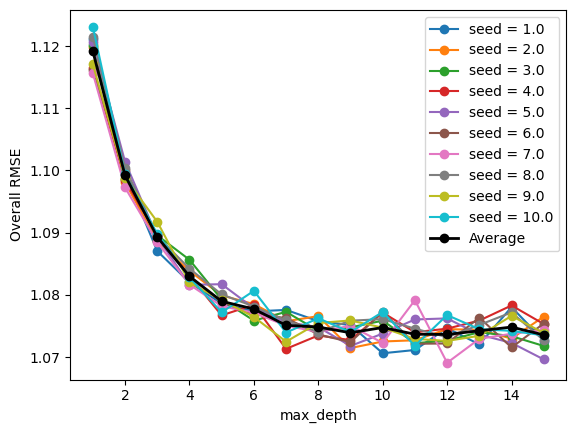

max_depth with minimum average RMSE: 15.0 1.0735693932883117


In [ ]:
#Create slices for plotting
values = np.unique(output[:, 1])

for value in values:
    rows = output[output[:, 1] == value]
    rows = rows[np.argsort(rows[:, 0])]  # sort x-values for a clean line

    plt.plot(rows[:, 0], rows[:, 2], marker="o", label=f"seed = {value}")

# Average across seeds for each N_DEP (column 0)
n_deps = np.unique(output[:, 0])

avg_rows = np.array([
    [n_dep, output[output[:, 0] == n_dep, 2].mean()]
    for n_dep in n_deps
])

plt.plot(avg_rows[:, 0], avg_rows[:, 1],
        marker="o", color="black", linewidth=2, label="Average")

            
# Find the N_DEP with the lowest average
min_idx = np.argmin(avg_rows[:, 1])

plt.xlabel("max_depth")
plt.ylabel("Overall RMSE")
plt.legend()
plt.show()

print("max_depth with minimum average RMSE:", avg_rows[min_idx, 0], avg_rows[min_idx, 1])

In [45]:
n_ran = 10
output = np.empty((4 * n_ran, 3), dtype=object)

for i, N_FEAT in enumerate(["sqrt", "log2", 0.5, 1.0]):
    for j, RAN in enumerate(range(1,11)):
        row = i * n_ran + j 
        model = RandomForestRegressor(n_estimators=300, max_features=N_FEAT, max_depth=9, random_state=RAN, n_jobs=1)
        overall_rmse = random_forest.fit_model_with_normal_cv(development, X_dev, y_dev, model, THRESHOLD_MG_L = 10)
        output[row, 0] = N_FEAT
        output[row, 1] = RAN
        output[row, 2] = overall_rmse

print(output)

KeyboardInterrupt: 